# experiment_1 — YOLO26n 사전학습 가중치 + 합성 데이터 (train / val / test)

| 항목 | 내용 |
| --- | --- |
| 목적 | 공식 `yolo26n.pt`(COCO 사전학습)에서 시작해 광각 합성 데이터로 학습하고, **따로 떼어 둔 test 세트로 최종 평가** |
| 데이터 | `yolo/datasets/turtle_ninja` 의 합성 500장(wide_001)을 seed 고정으로 train / val / test 로 다시 나눔 |
| 기록 | 이 노트북의 셀 출력 + 실행 폴더(`~/pa-course/experiments/<RUN_ID>/`)에 로그·설정·지표 파일 |

**실행 방법 (둘 중 하나)**

1. VS Code / Jupyter에서 커널을 `.venv-yolo`로 고르고 위에서부터 차례로 실행 → 저장(Ctrl+S)하면 출력이 노트북에 남아요.
2. 터미널에서 한 번에 실행하고 출력까지 노트북에 저장:
   ```bash
   cd ~/바탕화면/git/Project2_Turtle_Ninja/yolo/train
   ~/pa-course/.venv-yolo/bin/jupyter nbconvert --to notebook --execute --inplace \
       --ExecutePreprocessor.timeout=-1 experiment_1.ipynb
   ```

처음 한 번만 커널 준비:
```bash
~/pa-course/.venv-yolo/bin/pip install ipykernel nbconvert
~/pa-course/.venv-yolo/bin/python -m ipykernel install --user --name venv-yolo --display-name "Python (.venv-yolo)"
```

**셀 순서**: 0 설정 → 1 로그 시작 → 2 환경 기록 → 3 클래스 정의 확인 → 4 train/val/test 나누기 → 5 데이터 통계·샘플 → 6 사전학습 가중치 받기 → 7 학습 → 8 학습 곡선 → 9 val·test 평가 → 10 test 예측 샘플 → 11 요약

## 0. 설정 — 실험마다 여기만 바꾸기

In [1]:
from pathlib import Path
from datetime import datetime

EXP_NAME = "experiment_1"
RUN_ID = f"{EXP_NAME}_{datetime.now():%Y%m%d_%H%M%S}"   # 다시 돌려도 이전 기록을 덮어쓰지 않음

HOME = Path.home()
REPO = HOME / "바탕화면/git/Project2_Turtle_Ninja"
SRC_DATASET = REPO / "yolo/datasets/turtle_ninja"            # convert_to_yolo.py 결과 (images/<split>, labels/<split>)
SRC_SPLITS = ["train", "val_sim"]                              # 여기 있는 사진을 전부 모아서 다시 나눔
SPLIT_SEED = 0
SPLIT_RATIO = {"train": 0.8, "val": 0.1, "test": 0.1}
SPLIT_DATASET = REPO / f"yolo/datasets/turtle_ninja_split_s{SPLIT_SEED}"   # git 제외 폴더 (datasets/)

WEIGHTS_DIR = REPO / "yolo/models"                             # *.pt 는 git 제외
PRETRAINED = WEIGHTS_DIR / "yolo26n.pt"

PROJECT = HOME / "pa-course/experiments"                       # 레포 밖. 결과·로그 저장
EXP_DIR = PROJECT / RUN_ID

TRAIN_CFG = dict(
    epochs=50,
    patience=20,          # val 성능이 20 epoch 동안 안 좋아지면 멈춤
    imgsz=1280,           # 광각 원본 1280x720
    batch=8,
    device=0,
    workers=8,
    seed=0,
    deterministic=True,
    optimizer="auto",
    close_mosaic=10,      # 마지막 10 epoch는 mosaic 끔
    hsv_h=0.015,          # 기본값. 가이드 권장 0.3은 experiment_2에서 비교
    pretrained=True,
    plots=True,
    save=True,
    verbose=True,
)
print("RUN_ID     :", RUN_ID)
print("EXP_DIR    :", EXP_DIR)
print("SRC        :", SRC_DATASET, SRC_SPLITS)
print("SPLIT      :", SPLIT_DATASET, SPLIT_RATIO, "seed", SPLIT_SEED)
print("PRETRAINED :", PRETRAINED)

RUN_ID     : experiment_1_20261022_152756
EXP_DIR    : /home/haeminkim/pa-course/experiments/experiment_1_20261022_152756
SRC        : /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/turtle_ninja ['train', 'val_sim']
SPLIT      : /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/turtle_ninja_split_s0 {'train': 0.8, 'val': 0.1, 'test': 0.1} seed 0
PRETRAINED : /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/models/yolo26n.pt


## 1. 로그 시작 — 이 셀 이후의 모든 출력이 `run.log`에도 저장돼요

In [2]:
import sys, json, logging

EXP_DIR.mkdir(parents=True, exist_ok=False)
LOG_PATH = EXP_DIR / "run.log"

class Tee:
    """화면 출력과 run.log에 동시에 쓰기 (노트북 출력은 그대로 남음)."""
    def __init__(self, stream, path):
        self.stream, self.file = stream, open(path, "a", encoding="utf-8", buffering=1)
    def write(self, s):
        self.stream.write(s)
        self.file.write(s)
        return len(s)
    def flush(self):
        self.stream.flush(); self.file.flush()
    def __getattr__(self, name):
        return getattr(self.stream, name)

if not isinstance(sys.stdout, Tee):
    sys.stdout = Tee(sys.stdout, LOG_PATH)
    sys.stderr = Tee(sys.stderr, LOG_PATH)

def save_json(name, obj):
    p = EXP_DIR / name
    p.write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
    print("saved", p)

save_json("config.json", dict(RUN_ID=RUN_ID, SRC_DATASET=SRC_DATASET, SRC_SPLITS=SRC_SPLITS,
                              SPLIT_SEED=SPLIT_SEED, SPLIT_RATIO=SPLIT_RATIO,
                              SPLIT_DATASET=SPLIT_DATASET, PRETRAINED=PRETRAINED, TRAIN_CFG=TRAIN_CFG))
print(f"[{datetime.now():%F %T}] 로그 시작 → {LOG_PATH}")

saved /home/haeminkim/pa-course/experiments/experiment_1_20261022_152756/config.json
[2026-10-22 15:27:56] 로그 시작 → /home/haeminkim/pa-course/experiments/experiment_1_20261022_152756/run.log


## 2. 환경 기록 — 버전·GPU·git 상태

In [3]:
import platform, subprocess
import torch, ultralytics

def git(*args):
    try:
        return subprocess.run(["git", "-C", str(REPO), *args], capture_output=True, text=True).stdout.strip()
    except Exception as e:
        return f"error: {e}"

env = dict(
    time=datetime.now().isoformat(timespec="seconds"),
    python=sys.version.split()[0],
    platform=platform.platform(),
    torch=torch.__version__,
    cuda_available=torch.cuda.is_available(),
    cuda=torch.version.cuda,
    gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    ultralytics=ultralytics.__version__,
    git_branch=git("rev-parse", "--abbrev-ref", "HEAD"),
    git_commit=git("rev-parse", "--short", "HEAD"),
    git_dirty_files=len([l for l in git("status", "--porcelain").splitlines() if l.strip()]),
)
for k, v in env.items():
    print(f"{k:16s} {v}")
save_json("env.json", env)
assert env["cuda_available"], "GPU가 안 잡혀요. 커널이 .venv-yolo인지 확인하세요."

time             2026-10-22T15:27:59
python           3.12.3
platform         Linux-7.0.0-38-generic-x86_64-with-glibc2.39
torch            2.11.0+cu128
cuda_available   True
cuda             12.8
gpu              NVIDIA GeForce RTX 5060 Laptop GPU
ultralytics      8.4.183
git_branch       feat/camera_calib
git_commit       5d48516
git_dirty_files  3
saved /home/haeminkim/pa-course/experiments/experiment_1_20261022_152756/env.json


## 3. 클래스 정의 — 학습 전에 눈으로 확인

`yolo/dataset_gen/convert_to_yolo.py`의 `merged` 방식(모양 구분 안 함) 기준이에요. 아래 표와 `data.yaml`의 `names`가 다르면 이 셀에서 멈춰요.

In [4]:
import yaml

CLASSES = [
    # id, 이름,          무엇인지,                                    sim 원본 라벨 (convert_to_yolo.py)
    (0, "qr",           "벽에 붙은 QR/바코드 판 (내용은 YOLO가 아니라 디코더가 읽음)", "qr"),
    (1, "puck",         "서 있는 퍽. 원기둥 Ø30x60mm, 사각 30x30x60mm 모두 포함 (색은 후처리 HSV)", "puck_cyl, puck_box"),
    (2, "puck_fallen",  "넘어진(누운) 퍽. 두 모양 모두 포함",                        "puck_cyl_fallen, puck_box_fallen"),
    (3, "signal_tower", "신호등 기둥 전체 (점등 색은 후처리로 판별)",                 "signal_tower"),
]
NOT_LABELED = {"wall_joint": "파란 벽 연결 부품. 라벨 없이 배경(hard negative)으로 학습"}

NAMES = {i: n for i, n, _, _ in CLASSES}
print(f"{'id':>2}  {'name':14s} {'sim 라벨':34s} 설명")
print("-" * 110)
for i, n, desc, src in CLASSES:
    print(f"{i:>2}  {n:14s} {src:34s} {desc}")
for n, desc in NOT_LABELED.items():
    print(f" -  {n:14s} {'(라벨 없음)':34s} {desc}")

src_yaml = yaml.safe_load((SRC_DATASET / "data.yaml").read_text(encoding="utf-8"))
src_names = {int(k): v for k, v in src_yaml["names"].items()} if isinstance(src_yaml["names"], dict) \
    else dict(enumerate(src_yaml["names"]))
print("\n원본 data.yaml names:", src_names)
assert src_names == NAMES, "클래스 정의가 원본 data.yaml과 달라요. 위 표나 변환 옵션을 확인하세요."
print("✔ 클래스 정의 일치")
save_json("classes.json", dict(classes=[dict(id=i, name=n, description=d, sim_labels=s) for i, n, d, s in CLASSES],
                               not_labeled=NOT_LABELED))

id  name           sim 라벨                             설명
--------------------------------------------------------------------------------------------------------------
 0  qr             qr                                 벽에 붙은 QR/바코드 판 (내용은 YOLO가 아니라 디코더가 읽음)
 1  puck           puck_cyl, puck_box                 서 있는 퍽. 원기둥 Ø30x60mm, 사각 30x30x60mm 모두 포함 (색은 후처리 HSV)
 2  puck_fallen    puck_cyl_fallen, puck_box_fallen   넘어진(누운) 퍽. 두 모양 모두 포함
 3  signal_tower   signal_tower                       신호등 기둥 전체 (점등 색은 후처리로 판별)
 -  wall_joint     (라벨 없음)                            파란 벽 연결 부품. 라벨 없이 배경(hard negative)으로 학습

원본 data.yaml names: {0: 'qr', 1: 'puck', 2: 'puck_fallen', 3: 'signal_tower'}
✔ 클래스 정의 일치
saved /home/haeminkim/pa-course/experiments/experiment_1_20261022_152756/classes.json


## 4. train / val / test 나누기

- 원본 폴더의 사진을 모두 모아 `SPLIT_SEED`로 섞고 8:1:1로 나눠요. 같은 seed면 항상 같은 결과예요.
- 사진·라벨을 복사하지 않고 **심볼릭 링크**로 새 폴더(`turtle_ninja_split_s0`)를 만들어요.
- 폴더가 이미 있으면 새로 만들지 않고, 저장된 목록(`split_manifest.csv`)과 같은지 확인만 해요.
- **test는 학습·조기 종료에 전혀 쓰지 않고** 마지막 9번 셀에서 한 번만 평가해요.

In [5]:
import csv, random, os

def collect_pairs():
    pairs = []
    for s in SRC_SPLITS:
        for img in sorted((SRC_DATASET / "images" / s).glob("*.png")):
            lbl = SRC_DATASET / "labels" / s / (img.stem + ".txt")
            assert lbl.exists(), f"라벨 없음: {lbl}"
            pairs.append((img, lbl))
    return pairs

pairs = collect_pairs()
print("원본 사진 수:", len(pairs), {s: len(list((SRC_DATASET / 'images' / s).glob('*.png'))) for s in SRC_SPLITS})

order = list(range(len(pairs)))
random.Random(SPLIT_SEED).shuffle(order)
n = len(order)
n_train = round(n * SPLIT_RATIO["train"]); n_val = round(n * SPLIT_RATIO["val"])
assign = {}
for k, idx in enumerate(order):
    assign[idx] = "train" if k < n_train else "val" if k < n_train + n_val else "test"

manifest = [(assign[i], pairs[i][0].name, str(pairs[i][0])) for i in range(n)]
manifest.sort()
manifest_path = SPLIT_DATASET / "split_manifest.csv"

if SPLIT_DATASET.exists():
    with open(manifest_path, encoding="utf-8") as f:
        old = [tuple(r) for r in csv.reader(f)][1:]
    assert old == [tuple(m) for m in manifest], "기존 split 폴더와 목록이 달라요. SPLIT_SEED나 원본이 바뀌었는지 확인하세요."
    print("기존 split 폴더 재사용:", SPLIT_DATASET)
else:
    for i, (img, lbl) in enumerate(pairs):
        s = assign[i]
        for kind, src in (("images", img), ("labels", lbl)):
            d = SPLIT_DATASET / kind / s
            d.mkdir(parents=True, exist_ok=True)
            os.symlink(src.resolve(), d / src.name)
    with open(manifest_path, "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f); w.writerow(["split", "file", "source"]); w.writerows(manifest)
    print("새 split 폴더 생성:", SPLIT_DATASET)

DATA_YAML = SPLIT_DATASET / "data.yaml"
DATA_YAML.write_text(yaml.safe_dump(dict(path=str(SPLIT_DATASET), train="images/train", val="images/val",
                                         test="images/test", names=NAMES), allow_unicode=True, sort_keys=False),
                     encoding="utf-8")
print(DATA_YAML.read_text(encoding="utf-8"))

import shutil
shutil.copy2(manifest_path, EXP_DIR / "split_manifest.csv")
shutil.copy2(DATA_YAML, EXP_DIR / "data.yaml")
for s in ("train", "val", "test"):
    print(f"{s:5s}: {sum(1 for v in assign.values() if v == s)}장")

원본 사진 수: 500 {'train': 450, 'val_sim': 50}
새 split 폴더 생성: /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/turtle_ninja_split_s0
path: /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/turtle_ninja_split_s0
train: images/train
val: images/val
test: images/test
names:
  0: qr
  1: puck
  2: puck_fallen
  3: signal_tower

train: 400장
val  : 50장
test : 50장


## 5. 데이터 통계와 라벨 샘플 — split마다 클래스 수가 고르게 들어갔는지 확인

split     사진    빈사진     상자            qr          puck   puck_fallen  signal_tower
train    400      5   1102             0           774           158           170
val       50      0    132             0            89            18            25
test      50      0    149             0            96            30            23
saved /home/haeminkim/pa-course/experiments/experiment_1_20261022_152756/dataset_stats.json
⚠ train에 'qr' 상자가 0개 → 이 클래스는 train 지표가 안 나와요
⚠ val에 'qr' 상자가 0개 → 이 클래스는 val 지표가 안 나와요
⚠ test에 'qr' 상자가 0개 → 이 클래스는 test 지표가 안 나와요


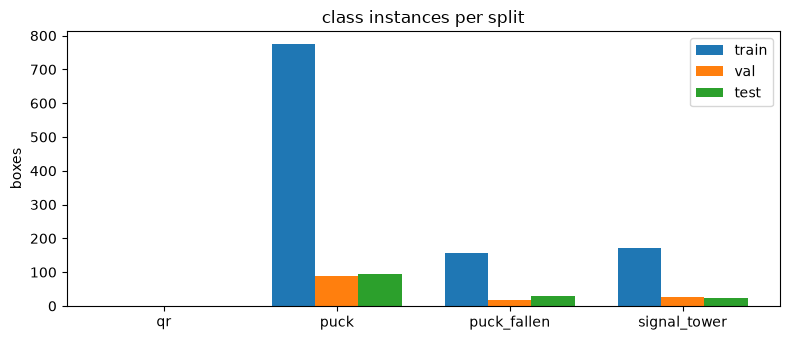

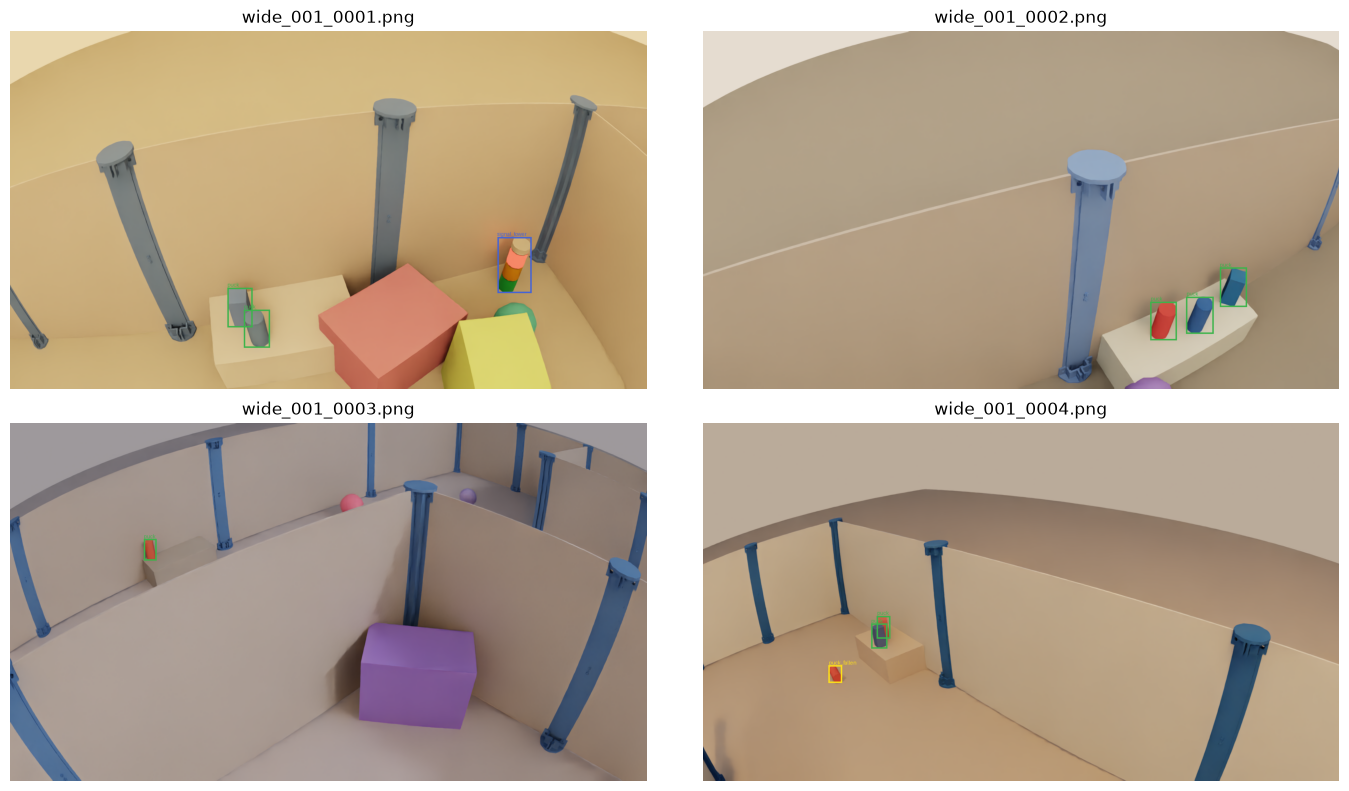

In [6]:
from collections import Counter
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

stats = {}
for s in ("train", "val", "test"):
    cnt, empty, n_img = Counter(), 0, 0
    for lbl in sorted((SPLIT_DATASET / "labels" / s).glob("*.txt")):
        rows = [l.split() for l in lbl.read_text().splitlines() if l.strip()]
        n_img += 1
        empty += not rows
        cnt.update(int(r[0]) for r in rows)
    stats[s] = dict(images=n_img, empty_images=empty, boxes=sum(cnt.values()),
                    per_class={NAMES[c]: cnt.get(c, 0) for c in NAMES})

print(f"{'split':6s} {'사진':>5s} {'빈사진':>6s} {'상자':>6s}  " + "  ".join(f"{NAMES[c]:>12s}" for c in NAMES))
for s, st in stats.items():
    print(f"{s:6s} {st['images']:5d} {st['empty_images']:6d} {st['boxes']:6d}  "
          + "  ".join(f"{st['per_class'][NAMES[c]]:12d}" for c in NAMES))
save_json("dataset_stats.json", stats)
for s, st in stats.items():
    for c in NAMES:
        if st["per_class"][NAMES[c]] == 0:
            print(f"⚠ {s}에 '{NAMES[c]}' 상자가 0개 → 이 클래스는 {s} 지표가 안 나와요")

fig, ax = plt.subplots(figsize=(8, 3.5))
w = 0.25
for k, s in enumerate(stats):
    ax.bar([c + (k - 1) * w for c in NAMES], [stats[s]["per_class"][NAMES[c]] for c in NAMES], w, label=s)
ax.set_xticks(list(NAMES)); ax.set_xticklabels(list(NAMES.values())); ax.set_ylabel("boxes"); ax.legend()
ax.set_title("class instances per split"); fig.tight_layout()
fig.savefig(EXP_DIR / "class_counts.png", dpi=120); plt.show()

COLORS = ["#e6194b", "#3cb44b", "#ffe119", "#4363d8"]
def draw(img_path, lbl_path):
    im = Image.open(img_path).convert("RGB"); W, H = im.size; d = ImageDraw.Draw(im)
    for l in lbl_path.read_text().splitlines():
        if not l.strip(): continue
        c, cx, cy, bw, bh = int(l.split()[0]), *map(float, l.split()[1:])
        x0, y0, x1, y1 = (cx - bw / 2) * W, (cy - bh / 2) * H, (cx + bw / 2) * W, (cy + bh / 2) * H
        d.rectangle([x0, y0, x1, y1], outline=COLORS[c % 4], width=3)
        d.text((x0, max(0, y0 - 12)), NAMES[c], fill=COLORS[c % 4])
    return im

samples = sorted((SPLIT_DATASET / "images" / "train").glob("*.png"))[:4]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for a, p in zip(axes.flat, samples):
    a.imshow(draw(p, SPLIT_DATASET / "labels" / "train" / (p.stem + ".txt"))); a.set_title(p.name); a.axis("off")
fig.tight_layout(); fig.savefig(EXP_DIR / "label_samples.png", dpi=80); plt.show()

## 6. 사전학습 가중치 받기 — `yolo26n.pt` (COCO 80클래스)

- Ultralytics 공식 배포 파일을 `yolo/models/yolo26n.pt`로 직접 내려받아요. 이미 있으면 다시 받지 않아요.
- 파일 크기와 SHA256을 기록해서 나중에 같은 가중치였는지 확인할 수 있게 해요.
- 학습을 시작하면 머리(head)는 우리 4클래스로 새로 만들고 나머지 층은 이 가중치를 이어받아요. 7번 셀 로그의 `Transferred N/M items` 줄이 그 증거예요.

In [7]:
import hashlib
from ultralytics import YOLO
from ultralytics.utils.downloads import attempt_download_asset

WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)
if not PRETRAINED.exists():
    print("다운로드:", PRETRAINED.name)
    got = Path(attempt_download_asset(str(PRETRAINED)))
    assert got.resolve() == PRETRAINED.resolve() and PRETRAINED.exists(), f"다운로드 실패: {got}"
else:
    print("이미 있음:", PRETRAINED)

sha = hashlib.sha256(PRETRAINED.read_bytes()).hexdigest()
pre = YOLO(str(PRETRAINED))
n_params = sum(p.numel() for p in pre.model.parameters())
weights_info = dict(path=PRETRAINED, size_bytes=PRETRAINED.stat().st_size, sha256=sha,
                    task=pre.task, n_classes=len(pre.names), params=n_params)
for k, v in weights_info.items():
    print(f"{k:11s} {v}")
print("사전학습 클래스 예시:", list(pre.names.values())[:8], "...")
pre.info(detailed=False)
save_json("pretrained.json", weights_info)
del pre

다운로드: yolo26n.pt
path        /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/models/yolo26n.pt
size_bytes  5544453
sha256      9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef
task        detect
n_classes   80
params      2572280
사전학습 클래스 예시: ['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck'] ...
YOLO26n summary: 260 layers, 2,572,280 parameters, 0 gradients, 6.2 GFLOPs
saved /home/haeminkim/pa-course/experiments/experiment_1_20261022_152756/pretrained.json


## 7. 학습 — 진행 로그는 이 셀 출력과 `run.log`, epoch별 수치는 `results.csv`

In [8]:
import time

model = YOLO(str(PRETRAINED))
t0 = time.time()
train_results = model.train(data=str(DATA_YAML), project=str(PROJECT), name=RUN_ID, exist_ok=True, **TRAIN_CFG)
train_min = (time.time() - t0) / 60
SAVE_DIR = Path(model.trainer.save_dir)
BEST = SAVE_DIR / "weights" / "best.pt"
print(f"\n학습 시간 {train_min:.1f}분 | 결과 폴더 {SAVE_DIR} | best {BEST.exists()}")

transfer = [l.strip() for l in LOG_PATH.read_text(encoding="utf-8", errors="ignore").splitlines() if "Transferred" in l]
print("사전학습 가중치 이어받기:", transfer[-1] if transfer else "⚠ 'Transferred' 줄을 못 찾음 — 위 로그 확인")
save_json("train_info.json", dict(train_minutes=round(train_min, 2), save_dir=SAVE_DIR, best=BEST,
                                  transferred=transfer[-1] if transfer else None))

Ultralytics 8.4.183 🚀 Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 7708MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/turtle_ninja_split_s0/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/home/haeminkim/바탕화면/git/Project2_T

## 8. 학습 곡선 — `results.csv`

epoch | box_loss | cls_loss | box_loss | cls_loss | precision(B) | recall(B) | mAP50(B) | mAP50-95(B)
  1 | 0.8809 | 68.5890 | 0.5571 | 34.7512 | 0.5714 | 0.4685 | 0.6036 | 0.4949
  2 | 0.8090 | 19.1708 | 0.5608 | 8.2147 | 0.9134 | 0.9092 | 0.9351 | 0.8117
  3 | 0.8428 | 5.8243 | 0.7662 | 3.8917 | 0.9450 | 0.9369 | 0.9535 | 0.8044
  4 | 0.8251 | 2.5844 | 0.6594 | 1.8657 | 0.9566 | 0.9110 | 0.9424 | 0.8314
  5 | 0.8005 | 1.4404 | 0.6724 | 1.2267 | 0.9845 | 0.9143 | 0.9579 | 0.8343
  6 | 0.7516 | 1.0398 | 0.6061 | 0.9190 | 0.9734 | 0.9070 | 0.9529 | 0.8391
  7 | 0.7408 | 0.7938 | 0.6177 | 0.6857 | 0.9893 | 0.9398 | 0.9624 | 0.8671
  8 | 0.6913 | 0.6962 | 0.6567 | 0.6175 | 0.9857 | 0.9560 | 0.9862 | 0.8809
  9 | 0.6975 | 0.6347 | 0.5267 | 0.5987 | 0.9598 | 0.9421 | 0.9637 | 0.8716
 10 | 0.6436 | 0.6353 | 0.6014 | 0.6898 | 0.9103 | 0.9278 | 0.9378 | 0.8540
 11 | 0.6496 | 0.5527 | 0.4977 | 0.5040 | 0.9816 | 0.9466 | 0.9707 | 0.8729
 12 | 0.6249 | 0.4944 | 0.4832 | 0.4444 | 0.9972 | 0.9462 |

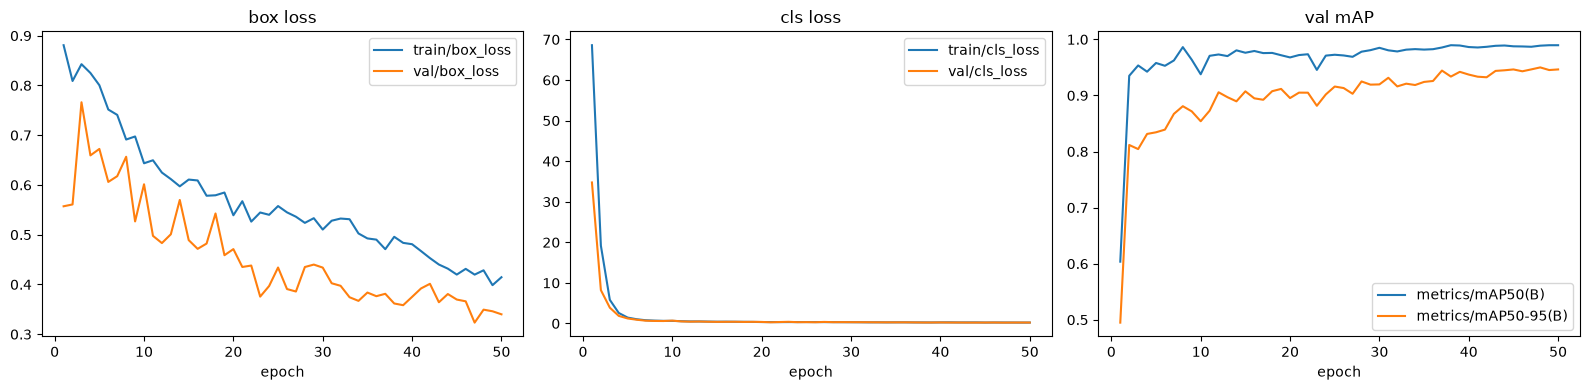

In [9]:
with open(SAVE_DIR / "results.csv", encoding="utf-8") as f:
    rows = [{k.strip(): v for k, v in r.items()} for r in csv.DictReader(f)]
cols = ["epoch", "train/box_loss", "train/cls_loss", "val/box_loss", "val/cls_loss",
        "metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]
cols = [c for c in cols if c in rows[0]]
print(" | ".join(c.split("/")[-1] for c in cols))
for r in rows:
    print(" | ".join(f"{float(r[c]):.4f}" if c != "epoch" else f"{int(float(r[c])):>3d}" for c in cols))

ep = [int(float(r["epoch"])) for r in rows]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for c in ("train/box_loss", "val/box_loss"):
    axes[0].plot(ep, [float(r[c]) for r in rows], label=c)
for c in ("train/cls_loss", "val/cls_loss"):
    axes[1].plot(ep, [float(r[c]) for r in rows], label=c)
for c in ("metrics/mAP50(B)", "metrics/mAP50-95(B)"):
    axes[2].plot(ep, [float(r[c]) for r in rows], label=c)
for a, t in zip(axes, ("box loss", "cls loss", "val mAP")):
    a.set_title(t); a.set_xlabel("epoch"); a.legend()
fig.tight_layout(); fig.savefig(EXP_DIR / "curves.png", dpi=120); plt.show()

## 9. 최종 평가 — best.pt로 val과 test 각각 (test는 여기서 처음 사용)

In [10]:
best = YOLO(str(BEST))
metrics = {}
for split in ("val", "test"):
    m = best.val(data=str(DATA_YAML), split=split, imgsz=TRAIN_CFG["imgsz"], batch=TRAIN_CFG["batch"],
                 device=TRAIN_CFG["device"], project=str(EXP_DIR), name=f"eval_{split}", exist_ok=True, plots=True)
    per_class = {}
    for k, c in enumerate(m.box.ap_class_index):
        p, r, ap50, ap = m.box.class_result(k)
        per_class[NAMES[int(c)]] = dict(P=round(float(p), 4), R=round(float(r), 4),
                                        mAP50=round(float(ap50), 4), mAP50_95=round(float(ap), 4))
    metrics[split] = dict(P=round(float(m.box.mp), 4), R=round(float(m.box.mr), 4),
                          mAP50=round(float(m.box.map50), 4), mAP50_95=round(float(m.box.map), 4),
                          per_class=per_class)

print(f"\n{'split':5s} {'class':14s} {'P':>6s} {'R':>6s} {'mAP50':>7s} {'mAP50-95':>9s}")
for split, mm in metrics.items():
    print(f"{split:5s} {'all':14s} {mm['P']:6.3f} {mm['R']:6.3f} {mm['mAP50']:7.3f} {mm['mAP50_95']:9.3f}")
    for name, pc in mm["per_class"].items():
        print(f"{'':5s} {name:14s} {pc['P']:6.3f} {pc['R']:6.3f} {pc['mAP50']:7.3f} {pc['mAP50_95']:9.3f}")
save_json("metrics.json", metrics)

Ultralytics 8.4.183 🚀 Python-3.12.3 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Laptop GPU, 7708MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5728.7±1071.5 MB/s, size: 447.6 KB)
val: Scanning /home/haeminkim/바탕화면/git/Project2_Turtle_Ninja/yolo/datasets/turtle_ninja_split_s0/labels/val.cache... 50 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 50/50 19.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 4.0it/s 1.7s0.2ss
                   all         50        132      0.992      0.953      0.989      0.944
                  puck         47         89          1      0.969      0.994      0.963
           puck_fallen         16         18      0.977      0.889      0.977      0.911
          signal_tower         25         25      0.997          1      0.995      0.958
Speed: 5.4ms preprocess, 7.7ms inference, 0.

## 10. test 예측 샘플 — confidence 0.5 이상 (planning 기준과 같음)

Results saved to /home/haeminkim/pa-course/experiments/experiment_1_20261022_152756/pred_test


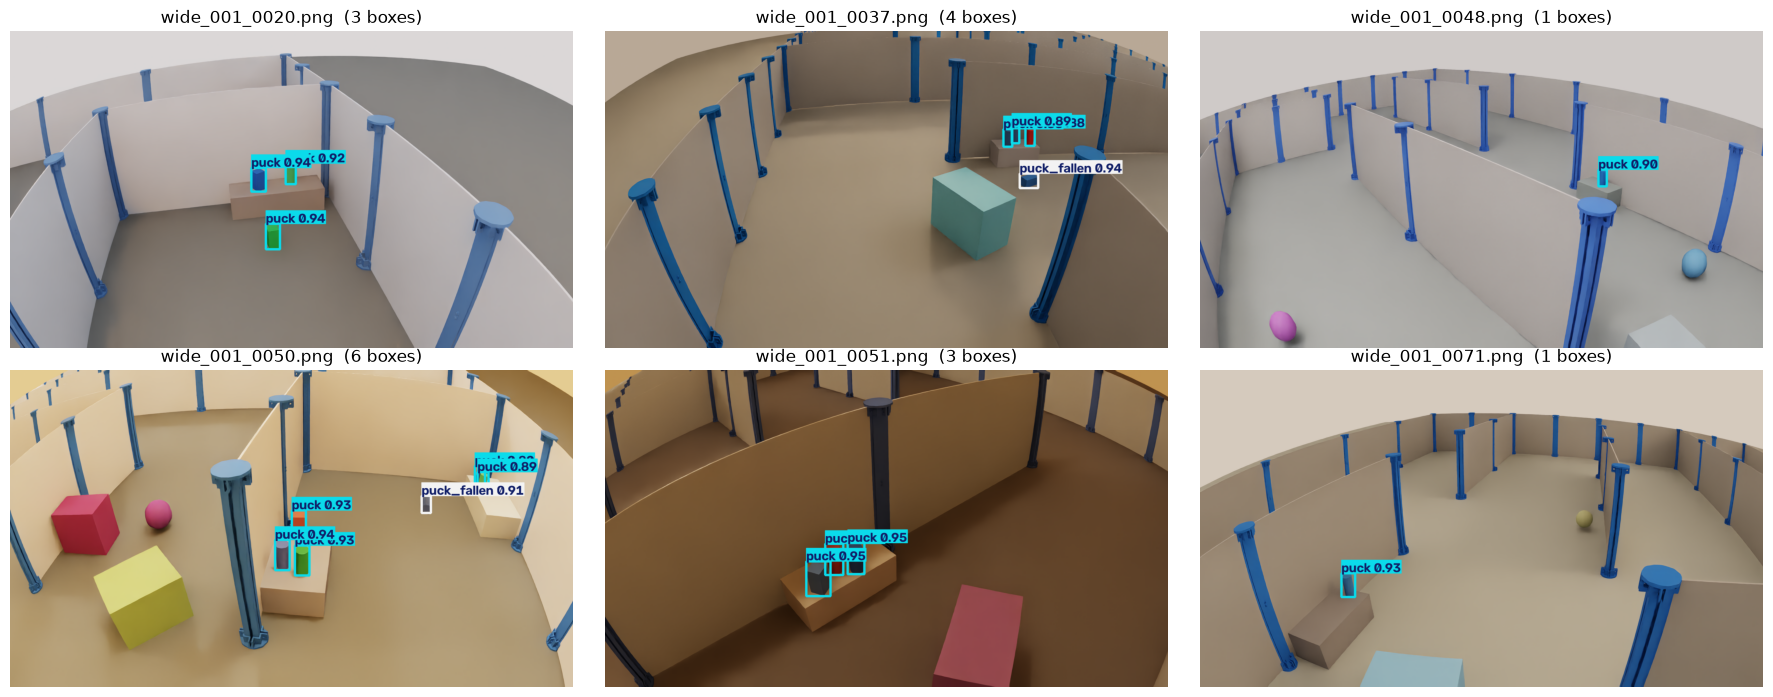

In [11]:
test_imgs = sorted((SPLIT_DATASET / "images" / "test").glob("*.png"))[:6]
preds = best.predict([str(p) for p in test_imgs], conf=0.5, imgsz=TRAIN_CFG["imgsz"], device=TRAIN_CFG["device"],
                     save=True, project=str(EXP_DIR), name="pred_test", exist_ok=True, verbose=False)
fig, axes = plt.subplots(2, 3, figsize=(18, 7))
for a, r in zip(axes.flat, preds):
    a.imshow(r.plot()[..., ::-1]); a.set_title(f"{Path(r.path).name}  ({len(r.boxes)} boxes)"); a.axis("off")
fig.tight_layout(); fig.savefig(EXP_DIR / "pred_test_samples.png", dpi=80); plt.show()

## 11. 요약 — `summary.md`로 저장 (일지·Notion에 붙여 넣기용)

In [12]:
lines = [f"# {RUN_ID}", "",
         f"- 시작 가중치: `{PRETRAINED.name}` (sha256 {sha[:12]}…), {weights_info['n_classes']}클래스 COCO 사전학습",
         f"- 가중치 이어받기: {transfer[-1] if transfer else '확인 필요'}",
         f"- 데이터: `{SPLIT_DATASET.name}` (seed {SPLIT_SEED}) — "
         + ", ".join(f"{s} {stats[s]['images']}장/{stats[s]['boxes']}상자" for s in stats),
         f"- 설정: " + ", ".join(f"{k}={v}" for k, v in TRAIN_CFG.items()),
         f"- 환경: torch {env['torch']}, CUDA {env['cuda']}, {env['gpu']}, ultralytics {env['ultralytics']}, "
         f"git {env['git_branch']}@{env['git_commit']} (변경 {env['git_dirty_files']}개)",
         f"- 학습 시간: {train_min:.1f}분, epoch {len(rows)}", "",
         "| split | class | P | R | mAP50 | mAP50-95 |", "| --- | --- | --- | --- | --- | --- |"]
for split, mm in metrics.items():
    lines.append(f"| {split} | all | {mm['P']:.3f} | {mm['R']:.3f} | {mm['mAP50']:.3f} | {mm['mAP50_95']:.3f} |")
    for name, pc in mm["per_class"].items():
        lines.append(f"| {split} | {name} | {pc['P']:.3f} | {pc['R']:.3f} | {pc['mAP50']:.3f} | {pc['mAP50_95']:.3f} |")
lines += ["", "주의: val·test 모두 합성 사진이라 실제 카메라 성능과 다를 수 있음 (val_real 없음)."]
(EXP_DIR / "summary.md").write_text("\n".join(lines) + "\n", encoding="utf-8")
print("\n".join(lines))

print("\n실행 폴더 파일:")
for p in sorted(EXP_DIR.iterdir()):
    print(" ", p.name + ("/" if p.is_dir() else ""))
print(f"\n[{datetime.now():%F %T}] 끝")

# experiment_1_20261022_152756

- 시작 가중치: `yolo26n.pt` (sha256 9b09cc8bf347…), 80클래스 COCO 사전학습
- 가중치 이어받기: Transferred 696/708 items from pretrained weights
- 데이터: `turtle_ninja_split_s0` (seed 0) — train 400장/1102상자, val 50장/132상자, test 50장/149상자
- 설정: epochs=50, patience=20, imgsz=1280, batch=8, device=0, workers=8, seed=0, deterministic=True, optimizer=auto, close_mosaic=10, hsv_h=0.015, pretrained=True, plots=True, save=True, verbose=True
- 환경: torch 2.11.0+cu128, CUDA 12.8, NVIDIA GeForce RTX 5060 Laptop GPU, ultralytics 8.4.183, git feat/camera_calib@5d48516 (변경 3개)
- 학습 시간: 9.5분, epoch 50

| split | class | P | R | mAP50 | mAP50-95 |
| --- | --- | --- | --- | --- | --- |
| val | all | 0.992 | 0.953 | 0.989 | 0.944 |
| val | puck | 1.000 | 0.969 | 0.995 | 0.963 |
| val | puck_fallen | 0.977 | 0.889 | 0.977 | 0.911 |
| val | signal_tower | 0.997 | 1.000 | 0.995 | 0.958 |
| test | all | 0.993 | 0.978 | 0.982 | 0.933 |
| test | puck | 0.995 | 0.969 | 0.985 | 0.947 |
| test | puck_fa